# 06. Auditoría de robustez: clásico frente a CNN (T72, T73, T74)

Los dos modelos sobre **las mismas 327 imágenes de test** y las mismas 19 condiciones (la original y 6 perturbaciones × 3 niveles), con la misma degradación y semilla por imagen (`src/audit.py`, `src/audit_cnn.py`).

Los números y las figuras se generan con `python -m src.audit`, `python -m src.audit_cnn --run <corrida>` y `python -m src.audit_figures`; este notebook solo los lee.

In [1]:
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
tabla = pd.read_csv(ROOT / "results/auditoria/tabla.csv")
f1 = tabla.pivot_table(index=["perturbacion", "nivel"], columns="modelo", values="f1_macro", sort=False).round(3)
fpr = tabla.pivot_table(index=["perturbacion", "nivel"], columns="modelo", values="fpr_normal", sort=False).round(3)
pd.concat({"F1 macro": f1, "falsas alarmas": fpr}, axis=1)

F1 macro        falsas alarmas       
modelo                 clasico    cnn        clasico    cnn
perturbacion    nivel                                      
original        0        0.954  0.967          0.005  0.000
brillo_oscuro   1        0.955  0.948          0.016  0.000
                2        0.935  0.967          0.027  0.000
                3        0.842  0.993          0.027  0.000
brillo_claro    1        0.971  0.926          0.005  0.000
                2        0.966  0.926          0.011  0.000
                3        0.852  0.935          0.055  0.005
gamma           1        0.902  0.926          0.011  0.000
                2        0.762  0.876          0.033  0.000
                3        0.599  0.820          0.187  0.000
ruido_gaussiano 1        0.266  0.985          0.011  0.000
                2        0.278  0.764          0.005  0.005
                3        0.277  0.416          0.016  0.011
sal_pimienta    1        0.278  0.694          0.005  0.220
                2        0.267  0.244          0.077  0.253
                3        0.232  0.221          0.275  0.335
jpeg            1        0.934  0.948          0.011  0.000
                2        0.975  0.985          0.005  0.000
                3        0.903  0.575          0.022  0.005

## 1. F1 frente a la severidad (T73)

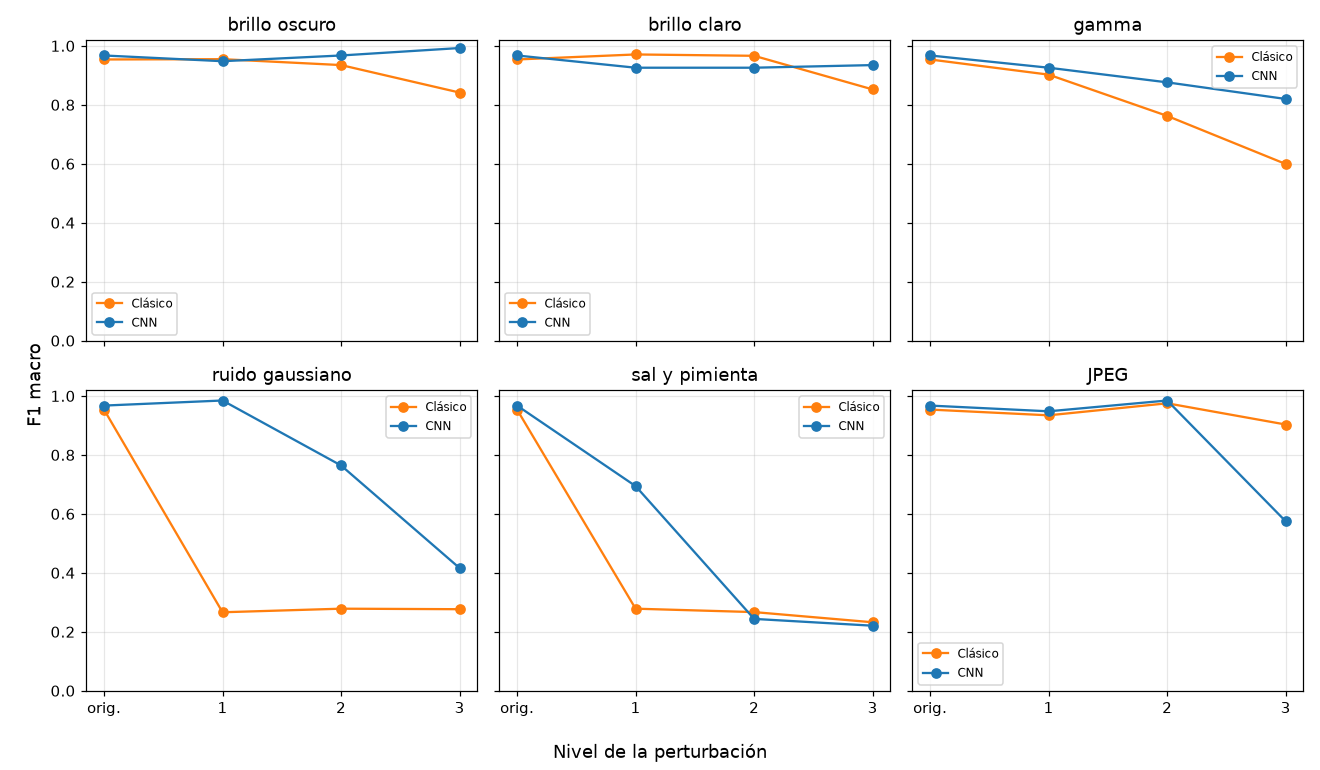

In [2]:
display(Image(filename=str(ROOT / "results/figuras/auditoria_f1_severidad.png")))

**Lectura:**

- **Luz (brillo oscuro, brillo claro, gamma):** la CNN casi no cae (gamma 3: 0,82 frente a 0,60 del clásico). El clásico pierde porque ORB encuentra menos puntos y la nitidez baja con el contraste.
- **Ruido gaussiano:** el clásico se desploma desde el nivel 1 (0,27): el ruido infla el Laplaciano y las desenfocadas parecen nítidas. La CNN resiste el nivel 1 (0,99) y cae después.
- **Sal y pimienta:** caen los dos. La diferencia es que el clásico se recupera con la **mediana** (sección 4 de `docs/auditoria.md`) y la CNN no tiene un filtro equivalente.
- **JPEG fuerte (nivel 3):** el clásico resiste (0,90) y la CNN cae a 0,58: confunde desenfocadas y tapadas con giradas.

## 2. Matrices de confusión cruzadas (T72)

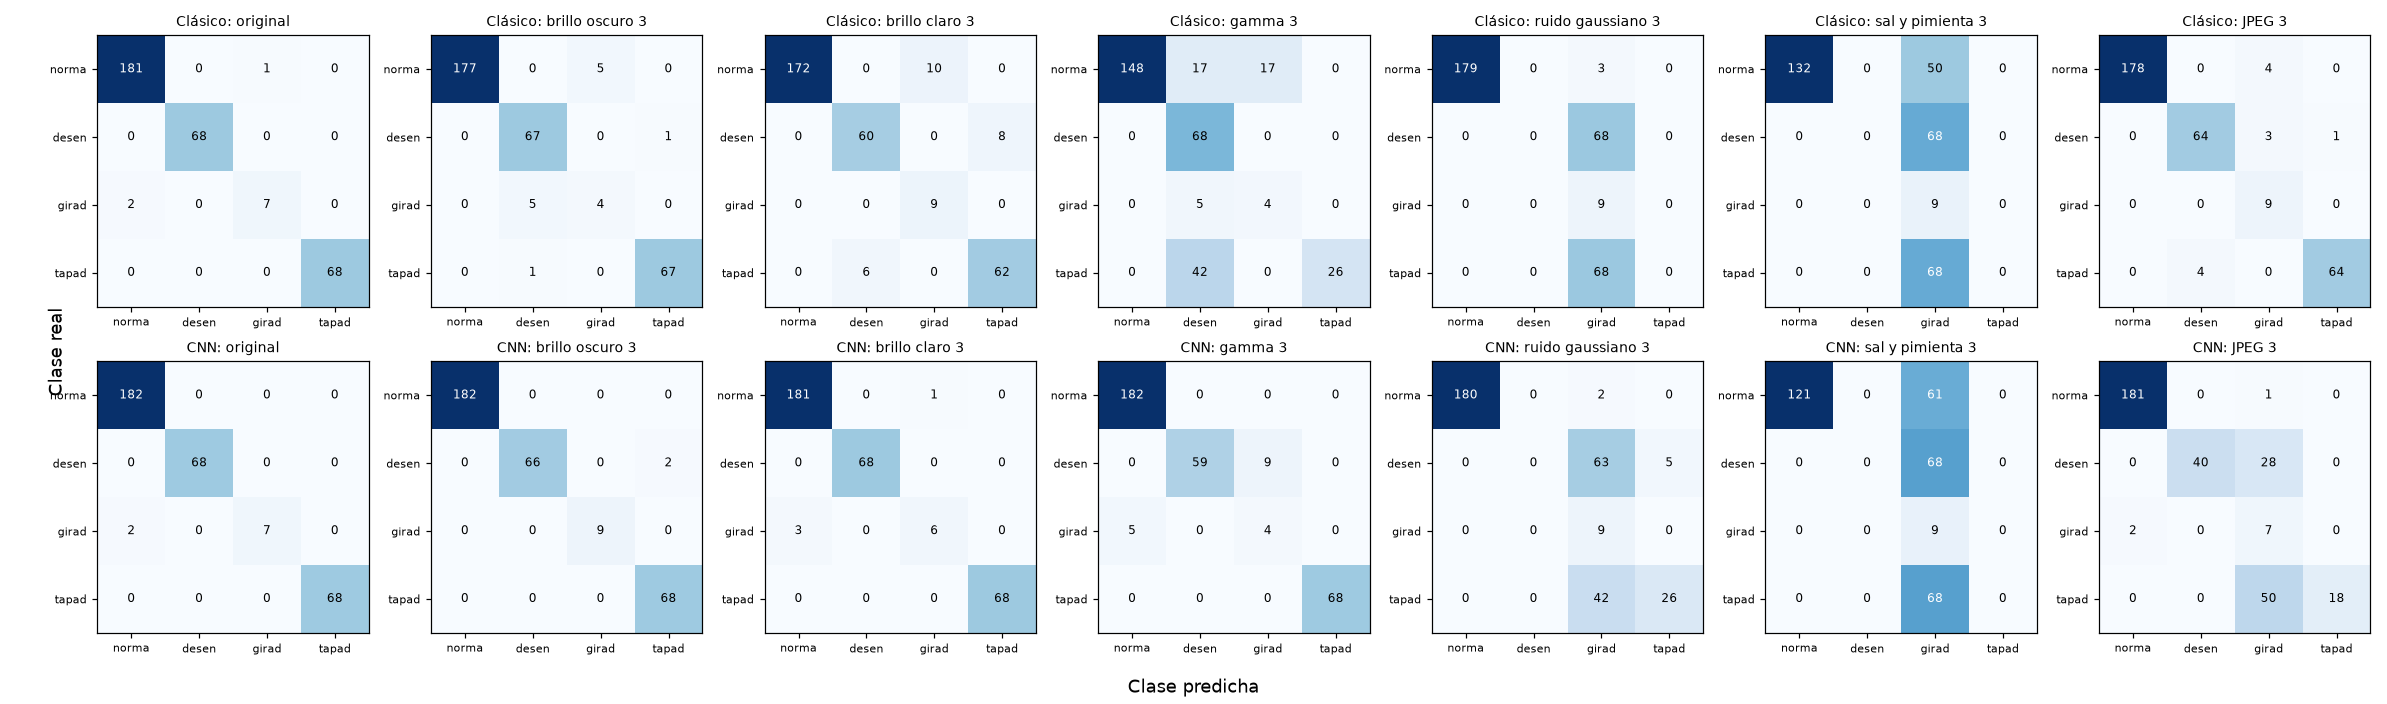

In [3]:
display(Image(filename=str(ROOT / "results/figuras/auditoria_matrices.png")))

**Lectura:** cada fila de matrices es un modelo y cada columna una condición crítica (la original y el nivel 3 de cada perturbación).

- Con **ruido gaussiano y sal y pimienta**, el clásico manda casi todo a **girada**: sin coincidencias ORB y con el Laplaciano inflado, la regla de nitidez dice "nítida" y la siguiente rama es girada.
- La **CNN con sal y pimienta** marca 61 de 182 normales como giradas: son las falsas alarmas (33,5 %).
- La **CNN con JPEG 3** manda 28 desenfocadas y 50 tapadas a girada: los bloques de 8×8 de la compresión parecen bordes.

## 3. Curvas ROC por condición (T73)

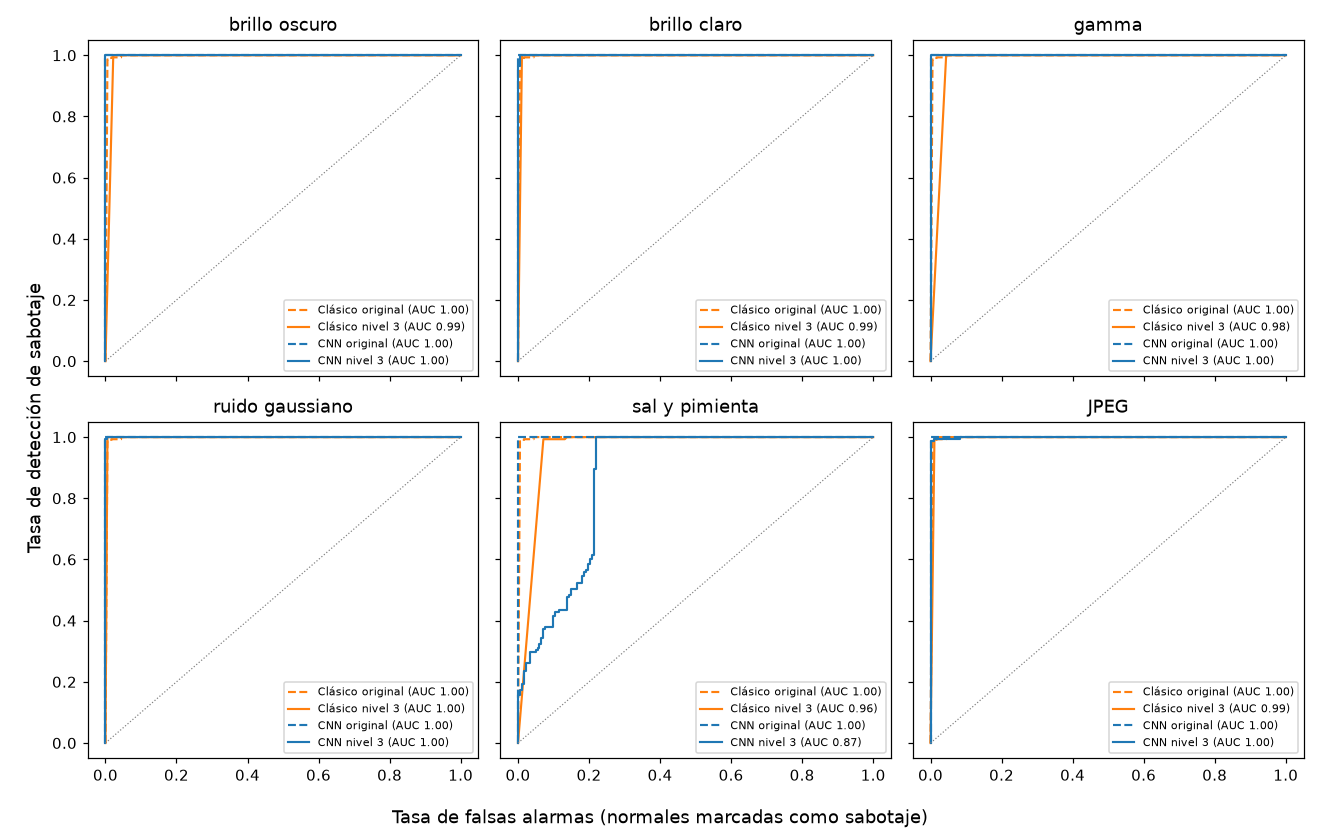

In [4]:
display(Image(filename=str(ROOT / "results/figuras/auditoria_roc.png")))

**Lectura:** el AUC mide si el modelo separa **normal frente a sabotaje**, sin importar el tipo. En las 38 combinaciones de modelo y condición el AUC es ≥ 0,96, salvo dos: **los dos modelos siguen detectando que hay sabotaje** aunque se equivoquen de tipo; por eso el F1 (que sí mira el tipo) cae mucho más que el AUC. Las dos excepciones son la **CNN con sal y pimienta** (AUC 0,94 en el nivel 2 y 0,87 en el nivel 3): sus puntuaciones de normales y saboteadas se mezclan, y eso coincide con sus falsas alarmas.

## 4. Conclusión para la defensa

Ningún modelo es más robusto en todo: la CNN gana con la luz y el ruido leve, el clásico con la compresión JPEG y es unas 4 veces más rápido (12 ms frente a 52 ms por cuadro). Y el clásico tiene algo que la CNN no: cada fallo se explica por un descriptor y se corrige con un filtro concreto (mediana, gamma inversa).